# 05 - Phân tích kết quả giữa kì (câu hỏi 1-5, phân tích lỗi)
Chỉ **đọc** xác suất đã lưu ở `results/preds/` (không huấn luyện lại). PhoBERT được chọn tự động theo val Macro-F1 cao nhất trong `baseline_results.csv`,
nên chạy lại notebook sau khi có lần chạy mới là kết quả tự cập nhật. Ngưỡng cố định 0,5 cho mọi mô hình (ngưỡng tối ưu để cuối kì).
Notebook **không in văn bản gốc**; chỉ xuất thống kê tổng hợp và danh sách id ca lỗi (xem văn bản bằng `python -m src.show_cases`).

> **Cách đọc/chạy.** Chỉ đọc xác suất đã lưu; chạy nhanh trên CPU. Phải chạy `04_phobert.ipynb` trước để có `results/tables/baseline_results.csv`. Chạy lại notebook này sau mỗi lần có kết quả mới là mọi con số tự cập nhật.
>
> **Thuật ngữ:**
> - **FN** (false negative): nhãn thật nhưng mô hình bỏ sót. **FP** (false positive): mô hình dự đoán có nhưng nhãn không có thật.
> - **Tương quan phi**: hệ số tương quan giữa hai nhãn nhị phân; dương = hay đi cùng nhau, âm = ít đi cùng nhau.
> - **Spearman**: tương quan thứ hạng giữa hai dãy số (-1 đến 1); p-value nhỏ cho thấy tương quan khó là ngẫu nhiên.
> - **Bootstrap**: lấy mẫu lại có hoàn lại các câu test nhiều lần để ước lượng khoảng tin cậy của một chênh lệch.
> - **Nhóm tần suất** head/mid/tail: theo số mẫu dương của nhãn trong train (định nghĩa ở `src/data.py`).
> Notebook **không in văn bản gốc** (license dataset); xem ca lỗi bằng `python -m src.show_cases`.

In [1]:
# Khởi tạo: nạp xác suất TEST của 3 mô hình (TF-IDF, BiLSTM, PhoBERT được chọn tự động theo val) và nhị phân hoá ở ngưỡng cố định 0.5 (YH).
# Chỉ đọc kết quả đã lưu, không huấn luyện lại.
# rng có seed cố định để các lần chọn ngẫu nhiên (bootstrap, chọn ca lỗi) tái lập được.
import sys, os
sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.data import *
from src.metrics import *
from src.features import text_flags

TAB, FIG, PRD = '../results/tables/', '../results/figures/', '../results/preds/'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
rng = np.random.default_rng(SEED)
data = load_all(); Ytr = label_matrix(data['train']); tiers = label_tiers(Ytr.sum(0)); trc = Ytr.sum(0)
res = pd.read_csv(TAB + 'baseline_results.csv', index_col=0)
ph = [r for r in res.index if r.startswith('phobert')]
CH = res.loc[ph, 'val_macro_f1'].idxmax()
MODELS = {'TF-IDF+LR': 'tfidf_lr', 'BiLSTM': 'bilstm', 'PhoBERT': CH}
ids, Yte, _ = load_preds(PRD + 'tfidf_lr_test.npz'); assert (ids == data['test'].id.values).all()
P = {k: load_preds(f'{PRD}{v}_test.npz')[2] for k, v in MODELS.items()}
YH = {k: binarize(p) for k, p in P.items()}          # ngưỡng cố định 0.5
Yte = Yte.astype(int); N = len(Yte)
print('PhoBERT được chọn (val Macro-F1 cao nhất):', CH)
print({k: round(compute_metrics(Yte, P[k])['macro_f1'], 4) for k in P}, '(test Macro-F1 @0.5)')

C:\Users\Admin\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PhoBERT được chọn (val Macro-F1 cao nhất): phobert_text_pw_sqrt_ep12


{'TF-IDF+LR': 0.5482, 'BiLSTM': 0.5115, 'PhoBERT': 0.6082} (test Macro-F1 @0.5)


## Câu 1-2: F1 từng nhãn và tương quan với tần suất huấn luyện

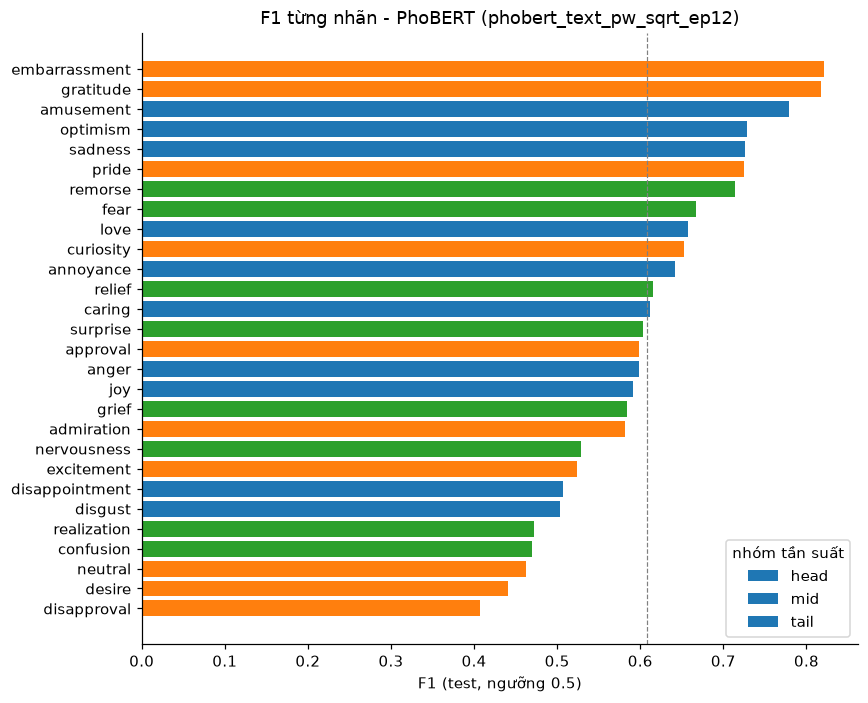

Cao nhất: embarrassment 0.821, gratitude 0.817, amusement 0.779, optimism 0.728, sadness 0.726
Thấp nhất: disapproval 0.408, desire 0.441, neutral 0.462, confusion 0.469, realization 0.472


In [2]:
# Câu 1: F1 từng nhãn (test) của 3 mô hình, lưu q12_f1_by_label.csv.
# Vẽ cột ngang cho PhoBERT, sắp theo F1 và tô màu theo nhóm tần suất; in 5 nhãn cao nhất / thấp nhất.
F1 = {k: per_label_f1(Yte, YH[k]) for k in YH}
q12 = pd.DataFrame({**{k: F1[k] for k in F1}, 'train_count': trc, 'tier': [tiers[l] for l in LABELS]}, index=LABELS).round(4)
q12.sort_values('PhoBERT', ascending=False).to_csv(TAB + 'q12_f1_by_label.csv')
tcol = {'head': '#1f77b4', 'mid': '#ff7f0e', 'tail': '#2ca02c'}
order = np.argsort(-F1['PhoBERT'])
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh([LABELS[i] for i in order][::-1], F1['PhoBERT'][order][::-1], color=[tcol[tiers[LABELS[i]]] for i in order][::-1])
for t, c in tcol.items(): ax.barh([], [], color=c, label=t)
ax.axvline(F1['PhoBERT'].mean(), ls='--', c='gray', lw=.8); ax.set_xlabel('F1 (test, ngưỡng 0.5)'); ax.set_title(f'F1 từng nhãn - PhoBERT ({CH})')
ax.legend(title='nhóm tần suất'); plt.tight_layout(); plt.savefig(FIG + 'q12_f1_by_label.png'); plt.show()
print('Cao nhất:', ', '.join(f'{LABELS[i]} {F1["PhoBERT"][i]:.3f}' for i in order[:5]))
print('Thấp nhất:', ', '.join(f'{LABELS[i]} {F1["PhoBERT"][i]:.3f}' for i in order[::-1][:5]))

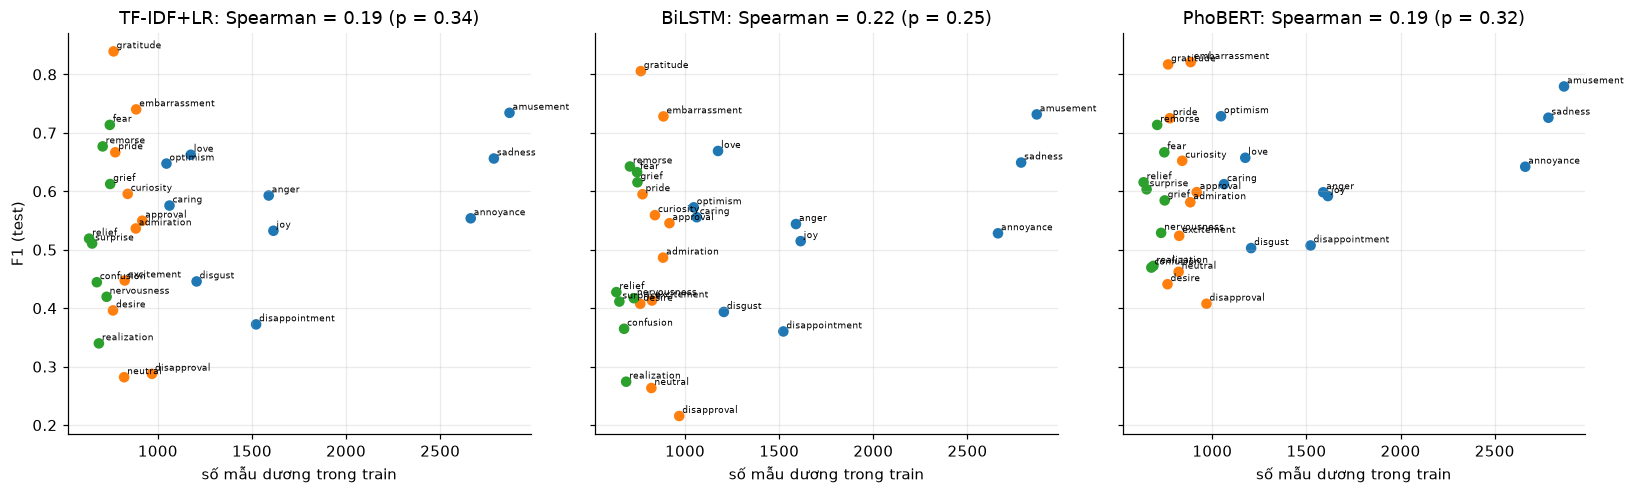

,spearman,p_value
model,,
TF-IDF+LR,0.188,0.339
BiLSTM,0.224,0.252
PhoBERT,0.195,0.320


,TF-IDF+LR,BiLSTM,PhoBERT
tier,,,
head,0.577,0.552,0.635
mid,0.534,0.502,0.603
tail,0.530,0.473,0.582


In [3]:
# Câu 2: vẽ F1 theo số mẫu train của nhãn (mỗi nhãn một điểm) cho từng mô hình, kèm hệ số Spearman (tương quan thứ hạng) và p-value.
# In F1 trung bình theo nhóm head/mid/tail. Chỉ có 28 nhãn nên kiểm định có độ mạnh thấp.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True); rows = []
for ax, k in zip(axes, F1):
    rho, p = spearmanr(F1[k], trc); rows.append({'model': k, 'spearman': round(rho, 3), 'p_value': round(p, 3)})
    ax.scatter(trc, F1[k], c=[tcol[tiers[l]] for l in LABELS], s=35)
    for i, l in enumerate(LABELS): ax.annotate(l, (trc[i], F1[k][i]), fontsize=6, xytext=(2, 2), textcoords='offset points')
    ax.set_title(f'{k}: Spearman = {rho:.2f} (p = {p:.2f})'); ax.set_xlabel('số mẫu dương trong train'); ax.grid(alpha=.25)
axes[0].set_ylabel('F1 (test)'); plt.tight_layout(); plt.savefig(FIG + 'q12_f1_vs_frequency.png'); plt.show()
q12_stats = pd.DataFrame(rows).set_index('model'); q12_stats.to_csv(TAB + 'q12_spearman.csv'); display(q12_stats)
display(q12.groupby('tier')[list(F1)].mean().round(3).loc[['head', 'mid', 'tail']])

## Câu 3: mô hình có giữ được phụ thuộc giữa các nhãn không?
So sánh **đồng xuất hiện nhãn thật** và **đồng xuất hiện nhãn dự đoán** trên test. Danh sách cặp quan tâm chọn theo tương quan phi trên **train** (không dùng nhãn test để chọn cặp).

In [4]:
# Câu 3 (phần 1): đo mức độ mô hình giữ cấu trúc phụ thuộc giữa các nhãn.
# - phi_mat: ma trận tương quan phi giữa mọi cặp nhãn (tính trên nhãn thật hoặc nhãn dự đoán).
#   Nhãn không bao giờ được dự đoán có độ lệch chuẩn 0 nên cho NaN; hàm sp() bỏ các cặp NaN khi tính Spearman.
# - So sánh theo thứ hạng 378 cặp nhãn. 'trần' = phi(train) với phi(test thật): cấu trúc ổn định giữa hai tập đến mức nào.
#   Các dòng còn lại so với phi của nhãn dự đoán.
# - Dòng cuối: số nhãn trung bình mỗi mẫu (thật so với dự đoán).
def phi_mat(Y):
    with np.errstate(invalid='ignore', divide='ignore'): return np.corrcoef(Y.T.astype(float))
iu = np.triu_indices(NUM_LABELS, 1)
phi_tr, phi_te = phi_mat(Ytr), phi_mat(Yte); phi_pr = {k: phi_mat(YH[k]) for k in YH}
def sp(a, b):
    m = ~(np.isnan(a) | np.isnan(b)); return spearmanr(a[m], b[m])[0], int(m.sum())
rows = [{'so sánh': 'trần: phi(train) với phi(test thật)', 'rho': round(sp(phi_tr[iu], phi_te[iu])[0], 3), 'số cặp': sp(phi_tr[iu], phi_te[iu])[1]}]
for k in YH:
    rows.append({'so sánh': f'{k}: phi(test thật) với phi(dự đoán)', 'rho': round(sp(phi_te[iu], phi_pr[k][iu])[0], 3), 'số cặp': sp(phi_te[iu], phi_pr[k][iu])[1]})
    rows.append({'so sánh': f'{k}: phi(train) với phi(dự đoán)', 'rho': round(sp(phi_tr[iu], phi_pr[k][iu])[0], 3), 'số cặp': sp(phi_tr[iu], phi_pr[k][iu])[1]})
q3a = pd.DataFrame(rows); q3a.to_csv(TAB + 'q3_phi_correlation.csv', index=False); display(q3a)
print('Số nhãn trung bình mỗi mẫu: thật', round(Yte.sum(1).mean(), 3), '|', {k: round(YH[k].sum(1).mean(), 3) for k in YH})

,so sánh,rho,số cặp
0,trần: phi(train) với phi(test thật),0.928,378
1,TF-IDF+LR: phi(test thật) với phi(dự đoán),0.837,378
2,TF-IDF+LR: phi(train) với phi(dự đoán),0.866,378
3,BiLSTM: phi(test thật) với phi(dự đoán),0.880,378
4,BiLSTM: phi(train) với phi(dự đoán),0.901,378
5,PhoBERT: phi(test thật) với phi(dự đoán),0.898,378
6,PhoBERT: phi(train) với phi(dự đoán),0.932,378


Số nhãn trung bình mỗi mẫu: thật 1.907 | {'TF-IDF+LR': np.float64(2.362), 'BiLSTM': np.float64(1.693), 'PhoBERT': np.float64(2.436)}


In [5]:
# Cặp được chọn theo tương quan phi trên TRAIN (không dùng nhãn test để chọn cặp).
# Với mỗi cặp: số mẫu test có cả hai nhãn THẬT, số mẫu mô hình dự đoán có cả hai, và số mẫu dự đoán ĐÚNG cả hai ('đúng cả đôi').
# 'dự đoán cùng có' lớn hơn 'thật cùng có' nghĩa là mô hình dự đoán cặp này nhiều hơn thực tế.
# 12 cặp có tương quan phi cao nhất trên TRAIN
top = np.argsort(-np.nan_to_num(phi_tr[iu], nan=-9))[:12]
rows = []
for t in top:
    i, j = iu[0][t], iu[1][t]
    true_both = int(((Yte[:, i] == 1) & (Yte[:, j] == 1)).sum()); row = {'cặp': f'{LABELS[i]} - {LABELS[j]}', 'phi_train': round(phi_tr[i, j], 2), 'test: thật cùng có': true_both}
    for k in YH:
        pb = int(((YH[k][:, i] == 1) & (YH[k][:, j] == 1)).sum()); ok = int(((YH[k][:, i] & YH[k][:, j] & Yte[:, i] & Yte[:, j]) == 1).sum())
        row[f'{k}: dự đoán cùng có'] = pb; row[f'{k}: đúng cả đôi'] = ok
    rows.append(row)
q3b = pd.DataFrame(rows).set_index('cặp'); q3b.to_csv(TAB + 'q3_top_pairs.csv'); display(q3b)
for k in YH:
    print(f'{k}: tổng lượt đồng xuất hiện dự đoán / thật = {int(sum((YH[k][:, a] & YH[k][:, b]).sum() for a, b in zip(*iu)))} / {int(sum((Yte[:, a] & Yte[:, b]).sum() for a, b in zip(*iu)))}')

,phi_train,test: thật cùng có,TF-IDF+LR: dự đoán cùng có,TF-IDF+LR: đúng cả đôi,BiLSTM: dự đoán cùng có,BiLSTM: đúng cả đôi,PhoBERT: dự đoán cùng có,PhoBERT: đúng cả đôi
cặp,,,,,,,,
fear - nervousness,0.41,43,51,24,47,21,63,26
sadness - grief,0.38,71,110,51,77,43,152,60
disappointment - sadness,0.36,127,128,48,121,50,171,73
excitement - joy,0.26,46,71,21,61,13,85,28
anger - annoyance,0.25,84,183,47,105,30,196,48
gratitude - relief,0.23,22,44,16,31,8,38,16
joy - love,0.22,42,64,24,53,21,103,29
optimism - caring,0.22,50,73,29,35,14,103,37
annoyance - disapproval,0.22,59,119,22,44,14,161,39


TF-IDF+LR: tổng lượt đồng xuất hiện dự đoán / thật = 5056 / 2466
BiLSTM: tổng lượt đồng xuất hiện dự đoán / thật = 2414 / 2466
PhoBERT: tổng lượt đồng xuất hiện dự đoán / thật = 4741 / 2466


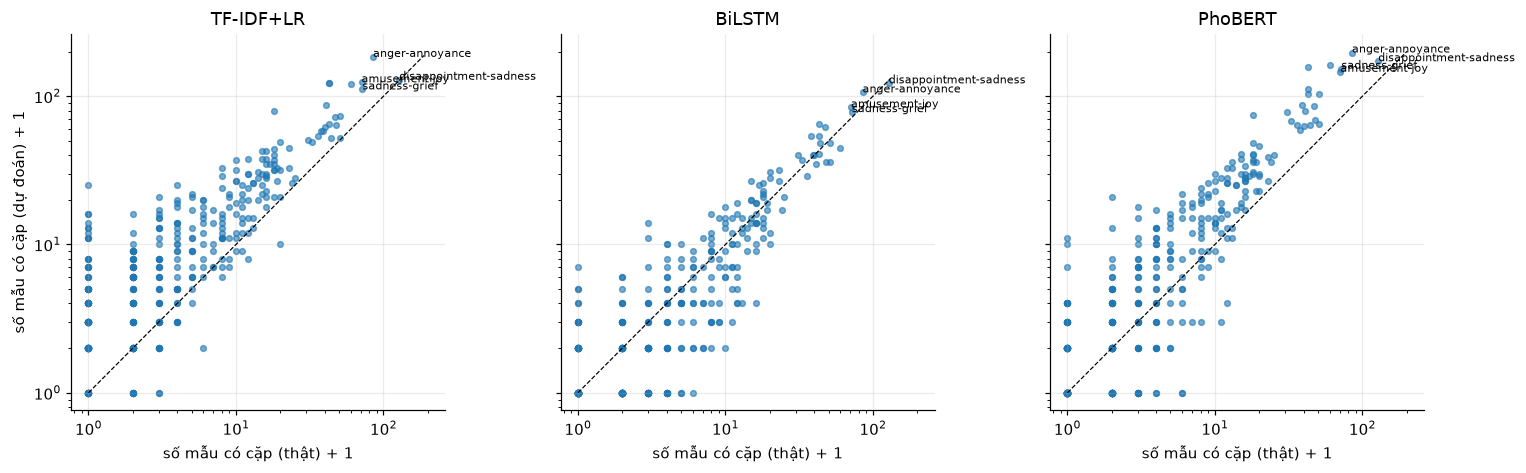

In [6]:
# Mỗi điểm là một cặp nhãn; đường đứt là y = x (số dự đoán bằng số thật).
# Điểm nằm trên đường = mô hình dự đoán cặp nhiều hơn thật. Cộng 1 để vẽ được thang log khi số đếm bằng 0.
# số lần đồng xuất hiện thật so với dự đoán, mọi cặp (log-log)
tc = np.array([(Yte[:, a] & Yte[:, b]).sum() for a, b in zip(*iu)])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, k in zip(axes, YH):
    pc = np.array([(YH[k][:, a] & YH[k][:, b]).sum() for a, b in zip(*iu)])
    ax.scatter(tc + 1, pc + 1, s=14, alpha=.6); lim = max(tc.max(), pc.max()) + 5
    ax.plot([1, lim], [1, lim], 'k--', lw=.8); ax.set_xscale('log'); ax.set_yscale('log')
    for t in np.argsort(-tc)[:4]: ax.annotate(f'{LABELS[iu[0][t]]}-{LABELS[iu[1][t]]}', (tc[t] + 1, pc[t] + 1), fontsize=7)
    ax.set_title(k); ax.set_xlabel('số mẫu có cặp (thật) + 1'); ax.grid(alpha=.25)
axes[0].set_ylabel('số mẫu có cặp (dự đoán) + 1'); plt.tight_layout(); plt.savefig(FIG + 'q3_cooccurrence_true_vs_pred.png'); plt.show()

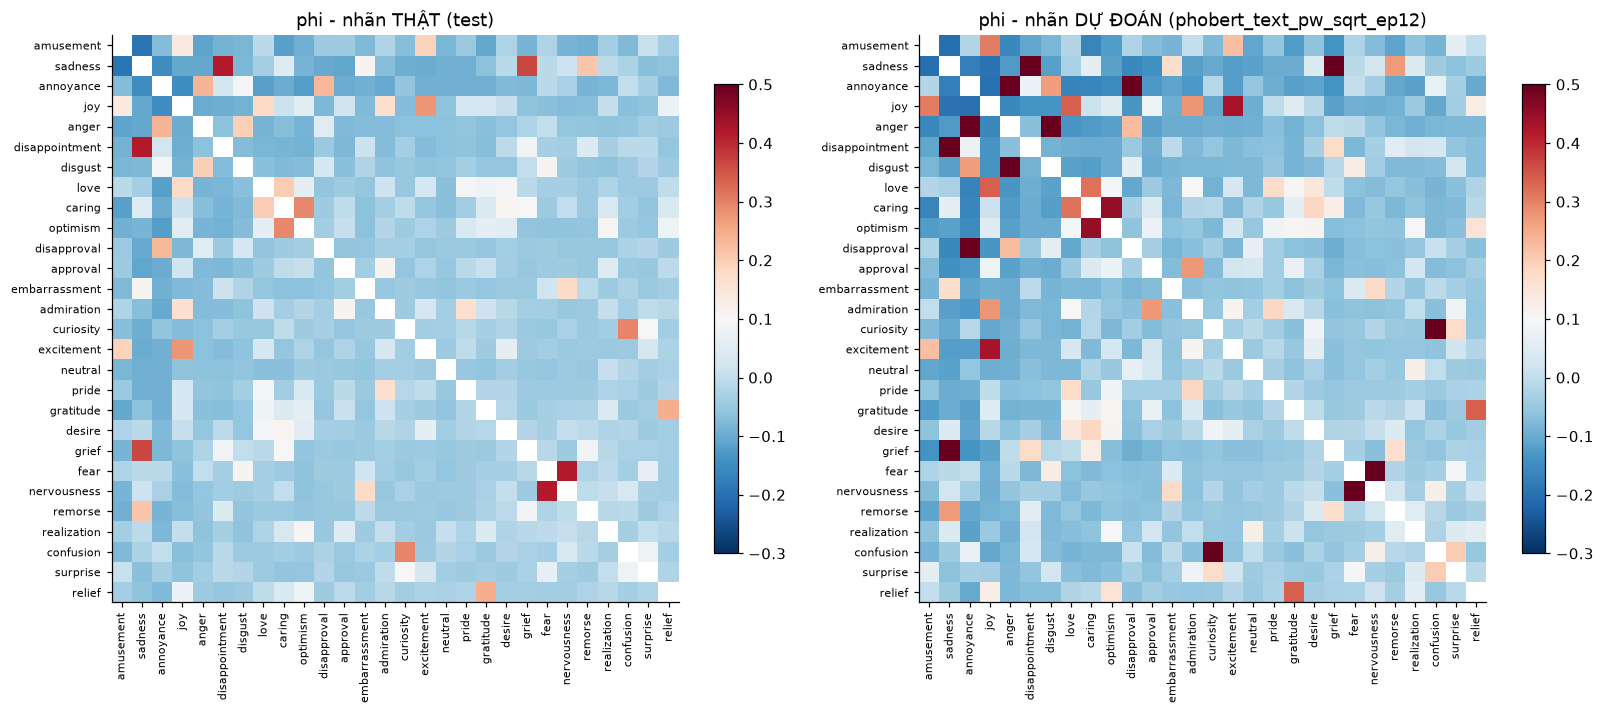

In [7]:
# Hai bản đồ nhiệt phi (nhãn thật so với nhãn dự đoán của PhoBERT), cùng thang màu và cùng thứ tự nhãn (phổ biến -> hiếm) để so sánh trực quan.
order = np.argsort(-trc); names = [LABELS[i] for i in order]; eye = np.eye(NUM_LABELS) > 0
fig, axes = plt.subplots(1, 2, figsize=(15, 6.8))
for ax, M, t in [(axes[0], phi_te, 'phi - nhãn THẬT (test)'), (axes[1], phi_pr['PhoBERT'], f'phi - nhãn DỰ ĐOÁN ({CH})')]:
    im = ax.imshow(np.where(eye, np.nan, M)[np.ix_(order, order)], vmin=-.3, vmax=.5, cmap='RdBu_r')
    ax.set_xticks(range(NUM_LABELS)); ax.set_yticks(range(NUM_LABELS)); ax.set_xticklabels(names, rotation=90, fontsize=7); ax.set_yticklabels(names, fontsize=7); ax.set_title(t); plt.colorbar(im, ax=ax, shrink=.7)
plt.tight_layout(); plt.savefig(FIG + 'q3_phi_heatmaps.png'); plt.show()

## Câu 4: PhoBERT so với BiLSTM theo kiểu văn bản
Các nhóm **chồng lấn** nhau (một câu có thể vừa ngắn vừa có emoji). Cờ kiểu văn bản là heuristic regex (`src/features.py`). Chỉ số: Micro-F1 trong từng nhóm
(Macro-F1 theo nhóm quá nhiễu vì nhiều nhãn gần như không có mẫu dương). Khoảng tin cậy 95% của **chênh lệch Micro-F1** bằng bootstrap trên các câu test (2000 lần lấy mẫu lại).

In [8]:
# Câu 4: so mô hình theo kiểu văn bản.
# - F: cờ kiểu văn bản của từng câu test (tính từ văn bản gốc, xem src/features.py). subsets: mặt nạ boolean cho từng nhóm; các nhóm CHỒNG LẤN nhau.
# - cnt[k]: với mỗi câu, số TP/FP/FN của mô hình k (đếm trên 28 nhãn).
#   Micro-F1 của một nhóm = 2*TP / (2*TP + FP + FN), cộng trên các câu trong nhóm.
# - Bootstrap: lấy mẫu lại các câu của nhóm B = 2000 lần (có hoàn lại), tính chênh lệch Micro-F1 giữa hai mô hình trên cùng mẫu lại,
#   rồi lấy phân vị 2,5% và 97,5% làm khoảng tin cậy 95%. Khoảng không chứa 0 nghĩa là chênh lệch vượt nhiễu do mẫu test
#   (chưa tính nhiễu do seed huấn luyện).
# - Dùng Micro-F1 vì Macro-F1 theo nhóm nhỏ quá nhiễu (nhiều nhãn gần như không có mẫu dương).
F = text_flags(data['test'].text)
subsets = {'Tất cả': np.ones(N, bool), 'Câu ngắn (<= 5 token)': F.short.values, 'Câu dài (>= 30 token)': F.long.values,
           'Có emoji': F.emoji.values, 'Nhiều emoji (>= 2)': (F.n_emoji >= 2).values, 'Có teencode': F.teencode.values,
           'Kéo dài ký tự': F.elong.values, 'Không emoji/teencode/kéo dài': ~(F.emoji | F.teencode | F.elong).values}
cnt = {}
for k in YH:
    Yh = YH[k].astype(int); cnt[k] = {'tp': (Yte & Yh).sum(1), 'fp': ((1 - Yte) & Yh).sum(1), 'fn': (Yte & (1 - Yh)).sum(1)}
def micro(k, idx):
    tp, fp, fn = (cnt[k][x][idx].sum(-1) for x in ('tp', 'fp', 'fn')); return 2 * tp / np.maximum(2 * tp + fp + fn, 1)
def samp_f1(k, idx):
    c = cnt[k]; return float(np.mean(2 * c['tp'][idx] / np.maximum(2 * c['tp'][idx] + c['fp'][idx] + c['fn'][idx], 1)))
B = 2000; rows = []
for name, m in subsets.items():
    idx = np.where(m)[0]; boot = rng.choice(idx, size=(B, len(idx)))  # ma trận (B x số câu) chỉ số câu lấy mẫu lại có hoàn lại
    row = {'nhóm': name, 'số câu': len(idx), '% test': round(100 * len(idx) / N, 1)}
    for k in YH: row[f'Micro-F1 {k}'] = round(float(micro(k, idx)), 4)
    for a, b in [('PhoBERT', 'BiLSTM'), ('PhoBERT', 'TF-IDF+LR')]:
        d = micro(a, boot) - micro(b, boot); lo, hi = np.percentile(d, [2.5, 97.5])
        row[f'{a} - {b}'] = round(float(micro(a, idx) - micro(b, idx)), 4); row[f'CI95 {a}-{b}'] = f'[{lo:+.3f}, {hi:+.3f}]'
        row[f'khác 0? {a}-{b}'] = 'có' if (lo > 0 or hi < 0) else 'không'
    for k in YH: row[f'F1/câu {k}'] = round(samp_f1(k, idx), 4)
    rows.append(row)
q4 = pd.DataFrame(rows).set_index('nhóm'); q4.to_csv(TAB + 'q4_subset_results.csv')
display(q4[['số câu', '% test'] + [f'Micro-F1 {k}' for k in YH] + ['PhoBERT - BiLSTM', 'CI95 PhoBERT-BiLSTM', 'khác 0? PhoBERT-BiLSTM']])
display(q4[['PhoBERT - TF-IDF+LR', 'CI95 PhoBERT-TF-IDF+LR', 'khác 0? PhoBERT-TF-IDF+LR']])

,số câu,% test,Micro-F1 TF-IDF+LR,Micro-F1 BiLSTM,Micro-F1 PhoBERT,PhoBERT - BiLSTM,CI95 PhoBERT-BiLSTM,khác 0? PhoBERT-BiLSTM
nhóm,,,,,,,,
Tất cả,2067,100.0,0.5630,0.5408,0.6240,0.0833,"[+0.070, +0.097]",có
Câu ngắn (<= 5 token),337,16.3,0.6078,0.6146,0.6789,0.0643,"[+0.031, +0.100]",có
Câu dài (>= 30 token),283,13.7,0.5347,0.4868,0.6126,0.1258,"[+0.090, +0.162]",có
Có emoji,536,25.9,0.6196,0.6049,0.6499,0.0449,"[+0.021, +0.069]",có
Nhiều emoji (>= 2),188,9.1,0.6290,0.6518,0.6882,0.0364,"[-0.003, +0.073]",không
Có teencode,347,16.8,0.5250,0.4939,0.5956,0.1017,"[+0.068, +0.137]",có
Kéo dài ký tự,265,12.8,0.6179,0.5931,0.6706,0.0775,"[+0.043, +0.113]",có
Không emoji/teencode/kéo dài,1143,55.3,0.5424,0.5136,0.6133,0.0997,"[+0.080, +0.118]",có


,PhoBERT - TF-IDF+LR,CI95 PhoBERT-TF-IDF+LR,khác 0? PhoBERT-TF-IDF+LR
nhóm,,,
Tất cả,0.0610,"[+0.048, +0.074]",có
Câu ngắn (<= 5 token),0.0711,"[+0.038, +0.102]",có
Câu dài (>= 30 token),0.0778,"[+0.047, +0.107]",có
Có emoji,0.0302,"[+0.007, +0.051]",có
Nhiều emoji (>= 2),0.0593,"[+0.024, +0.094]",có
Có teencode,0.0706,"[+0.039, +0.102]",có
Kéo dài ký tự,0.0527,"[+0.022, +0.084]",có
Không emoji/teencode/kéo dài,0.0709,"[+0.053, +0.089]",có


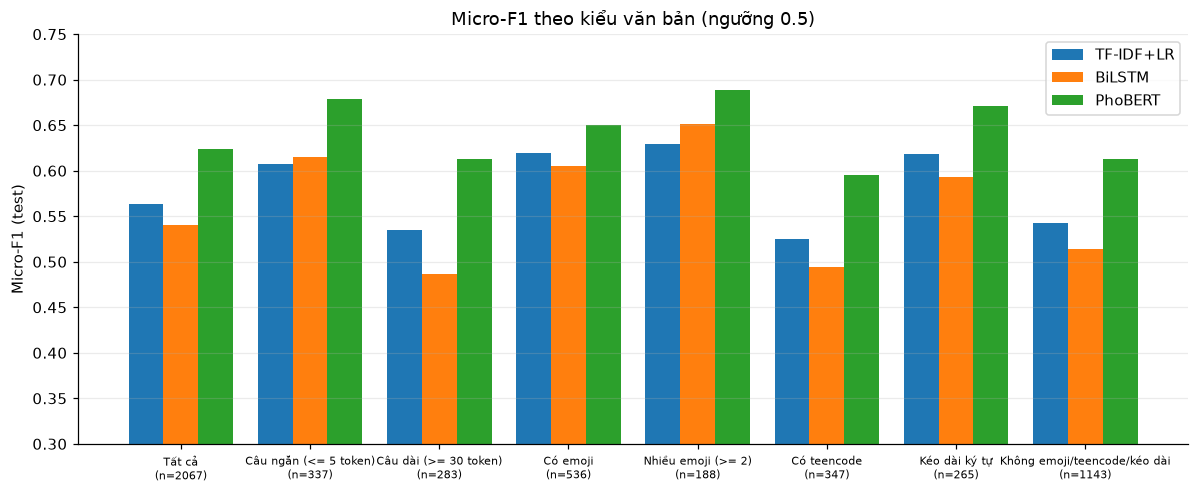

In [9]:
# Biểu đồ cột Micro-F1 của 3 mô hình theo từng nhóm (n = số câu của nhóm).
fig, ax = plt.subplots(figsize=(11, 4.6)); w = .27; x = np.arange(len(q4))
for j, k in enumerate(YH): ax.bar(x + (j - 1) * w, q4[f'Micro-F1 {k}'], w, label=k)
ax.set_xticks(x); ax.set_xticklabels([f'{n}\n(n={c})' for n, c in zip(q4.index, q4['số câu'])], fontsize=7); ax.set_ylabel('Micro-F1 (test)')
ax.set_ylim(.3, .75); ax.legend(); ax.set_title('Micro-F1 theo kiểu văn bản (ngưỡng 0.5)'); ax.grid(axis='y', alpha=.25); plt.tight_layout(); plt.savefig(FIG + 'q4_subsets.png'); plt.show()

## Phân tích lỗi (PhoBERT được chọn, ngưỡng 0.5)
Thống kê tổng hợp và **danh sách id** ca lỗi; không lưu văn bản. Để đọc ca cụ thể: `python -m src.show_cases --group fn_random` (chỉ in ra màn hình).

In [10]:
# Phân tích lỗi cho PhoBERT được chọn (ngưỡng 0.5). Y_ = nhãn thật, Yh_ = nhãn dự đoán, p_ = xác suất.
# FN = nhãn thật bị bỏ sót, FP = nhãn dự đoán thừa, TP = dự đoán đúng; thống kê theo từng nhãn và tổng theo nhóm head/mid/tail.
Y_, Yh_, p_ = Yte, YH['PhoBERT'].astype(int), P['PhoBERT']
tp, fp, fn = ((Y_ & Yh_).sum(0), ((1 - Y_) & Yh_).sum(0), (Y_ & (1 - Yh_)).sum(0))
err = pd.DataFrame({'tp': tp, 'fp': fp, 'fn': fn, 'precision': tp / np.maximum(tp + fp, 1), 'recall': tp / np.maximum(tp + fn, 1), 'tier': [tiers[l] for l in LABELS]}, index=LABELS).round(3)
err.to_csv(TAB + 'error_per_label_phobert.csv'); print('Tổng FN (cặp mẫu-nhãn bị bỏ sót):', int(fn.sum()), '| tổng FP (nhãn dự đoán thừa):', int(fp.sum()))
display(err.groupby('tier')[['tp', 'fp', 'fn']].sum().loc[['head', 'mid', 'tail']]); display(err.sort_values('fn', ascending=False).head(8))

Tổng FN (cặp mẫu-nhãn bị bỏ sót): 1141 | tổng FP (nhãn dự đoán thừa): 2234


,tp,fp,fn
tier,,,
head,1659,1210,569
mid,687,596,336
tail,455,428,236


,tp,fp,fn,precision,recall,tier
annoyance,243,171,100,0.587,0.708,head
disappointment,104,109,93,0.488,0.528,head
sadness,278,143,67,0.660,0.806,head
amusement,309,110,65,0.737,0.826,head
neutral,52,57,64,0.477,0.448,mid
joy,145,141,59,0.507,0.711,head
disgust,89,124,52,0.418,0.631,head
anger,140,139,49,0.502,0.741,head


In [11]:
# miss / spur là mặt nạ (mẫu x nhãn) cho FN / FP. Tích ma trận miss^T @ spur đếm, với mỗi cặp (i, j), số mẫu mà nhãn i thật bị bỏ sót
# đồng thời nhãn j bị dự đoán thừa. Bỏ đường chéo và lấy 15 cặp lớn nhất.
# Nhãn hay bị nhầm với nhau: M[i, j] = số mẫu có nhãn i THẬT mà không dự đoán i, đồng thời dự đoán j nhưng j không thật
miss = (Y_ == 1) & (Yh_ == 0); spur = (Y_ == 0) & (Yh_ == 1)
M = miss.T.astype(int) @ spur.astype(int); np.fill_diagonal(M, 0)
top = np.dstack(np.unravel_index(np.argsort(-M.ravel())[:15], M.shape))[0]
conf = pd.DataFrame([{'nhãn thật bị bỏ sót': LABELS[i], 'bị nhầm thành': LABELS[j], 'số mẫu': int(M[i, j]), 'phi train (i,j)': round(phi_tr[i, j], 2)} for i, j in top])
conf.to_csv(TAB + 'confused_pairs_phobert.csv', index=False); display(conf)

,nhãn thật bị bỏ sót,bị nhầm thành,số mẫu,"phi train (i,j)"
0,annoyance,sadness,21,-0.12
1,disgust,disapproval,18,0.02
2,disappointment,disapproval,17,-0.04
3,annoyance,disgust,16,0.08
4,annoyance,anger,14,0.25
5,sadness,annoyance,13,-0.12
6,disappointment,amusement,13,-0.10
7,disapproval,disgust,12,0.02
8,annoyance,disappointment,12,0.05
9,disgust,annoyance,12,0.08


In [12]:
# Chất lượng theo số nhãn thật |Y|:
# - F1/câu = 2*|giao| / (|thật| + |dự đoán|); Jaccard = |giao| / |hợp|.
# - Số nhãn dự đoán trung bình và tỉ lệ khớp hoàn toàn (đúng cả 28 nhãn).
# Nhóm >=4 được gộp vì rất ít mẫu.
# Theo số nhãn thật |Y|
card = Y_.sum(1); inter = (Y_ & Yh_).sum(1); union = np.maximum((Y_ | Yh_).sum(1), 1)
f1s = 2 * inter / np.maximum(Y_.sum(1) + Yh_.sum(1), 1)
grp = np.where(card >= 4, '>=4', card.astype(str))
bycard = pd.DataFrame({'|Y|': grp, 'F1/câu': f1s, 'Jaccard': inter / union, 'số nhãn dự đoán': Yh_.sum(1), 'khớp hoàn toàn': (Y_ == Yh_).all(1)}).groupby('|Y|').agg(
    số_câu=('F1/câu', 'size'), F1_câu=('F1/câu', 'mean'), Jaccard=('Jaccard', 'mean'), nhãn_dự_đoán=('số nhãn dự đoán', 'mean'), khớp_hoàn_toàn=('khớp hoàn toàn', 'mean')).round(3)
bycard.to_csv(TAB + 'error_by_cardinality_phobert.csv'); display(bycard)

,số_câu,F1_câu,Jaccard,nhãn_dự_đoán,khớp_hoàn_toàn
|Y|,,,,,
1,695,0.572,0.493,2.017,0.296
2,946,0.642,0.537,2.506,0.216
3,360,0.686,0.568,2.883,0.169
>=4,66,0.690,0.563,3.394,0.076


In [13]:
# fn_pairs / fp_pairs: các cặp (chỉ số mẫu, chỉ số nhãn) bị bỏ sót / dự đoán thừa.
# stratified(): chọn ngẫu nhiên có phân tầng theo nhóm tần suất của nhãn (7 head, 7 mid, 6 tail) để không chỉ nhìn các ca tệ nhất.
# 'extreme' = ca mô hình sai một cách rất chắc chắn (xác suất thấp nhất cho nhãn thật / cao nhất cho nhãn thừa).
# cases.csv chỉ lưu id, nhãn và xác suất (KHÔNG có văn bản); đọc văn bản bằng src/show_cases.py.
# Chọn ca để đọc thủ công: ngẫu nhiên phân tầng theo nhóm tần suất (tránh chỉ chọn ca tệ nhất) + các ca cực đoan
fn_pairs, fp_pairs = np.argwhere(miss), np.argwhere(spur)
QUOTA = {'head': 7, 'mid': 7, 'tail': 6}
def stratified(pairs, quota):
    out = []
    for t, q in quota.items():
        pool = [pr for pr in pairs if tiers[LABELS[pr[1]]] == t]; out += [pool[i] for i in rng.choice(len(pool), min(q, len(pool)), replace=False)]
    return np.array(out)
def case(group, s, c=None):
    return {'group': group, 'sample_id': data['test'].id.values[s], 'label': LABELS[c] if c is not None else '', 'prob': float(p_[s, c]) if c is not None else float('nan'),
            'true_labels': '; '.join(LABELS[i] for i in np.where(Y_[s])[0]), 'pred_labels': '; '.join(LABELS[i] for i in np.where(Yh_[s])[0]), 'n_true': int(Y_[s].sum())}
rows = [case('fn_random', s, c) for s, c in stratified(fn_pairs, QUOTA)] + [case('fp_random', s, c) for s, c in stratified(fp_pairs, QUOTA)]
rows += [case('fn_extreme', s, c) for s, c in fn_pairs[np.argsort(p_[fn_pairs[:, 0], fn_pairs[:, 1]])][:10]]     # nhãn thật bị chấm xác suất thấp nhất
rows += [case('fp_extreme', s, c) for s, c in fp_pairs[np.argsort(-p_[fp_pairs[:, 0], fp_pairs[:, 1]])][:10]]    # nhãn thừa được chấm xác suất cao nhất
multi = np.where(card >= 4)[0]; rows += [case('multi_label', s) for s in rng.choice(multi, min(10, len(multi)), replace=False)]
os.makedirs('../results/error_cases', exist_ok=True)
cases = pd.DataFrame(rows); cases.to_csv('../results/error_cases/cases.csv', index=False)
print(cases.group.value_counts().to_dict(), '| tier của FN random:', pd.Series([tiers[r['label']] for r in rows if r['group'] == 'fn_random']).value_counts().to_dict())

{'fn_random': 20, 'fp_random': 20, 'fn_extreme': 10, 'fp_extreme': 10, 'multi_label': 10} | tier của FN random: {'head': 7, 'mid': 7, 'tail': 6}


In [14]:
# File ghi chú chỉ chứa id; các cột nhận xét để trống cho người đọc ca điền (không ghi đè nếu file đã tồn tại).
# Mẫu ghi chú cho người đọc ca (chỉ chứa id; KHÔNG ghi đè nếu đã có file ghi chú)
path = '../reports/error_analysis_notes.md'
if os.path.exists(path): print('Đã có', path, '-> không ghi đè.')
else:
    titles = {'fn_random': 'Bỏ sót nhãn (FN) - ngẫu nhiên phân tầng theo nhóm tần suất', 'fp_random': 'Dự đoán thừa (FP) - ngẫu nhiên phân tầng', 'fn_extreme': 'Bỏ sót nhãn (FN) - mô hình rất chắc là KHÔNG có',
              'fp_extreme': 'Dự đoán thừa (FP) - mô hình rất chắc là CÓ', 'multi_label': 'Câu nhiều cảm xúc (|Y| >= 4)'}
    out = ['# Ghi chú phân tích lỗi (PhoBERT, test, ngưỡng 0.5)', '',
           f'Mô hình: `{CH}`. Đọc ca bằng `python -m src.show_cases --group <nhóm>`.', '',
           '**Quy tắc:** diễn đạt lại nội dung bằng lời của mình, **không chép nguyên văn** bình luận (license dataset không cho phân phối lại). Gợi ý nhóm lỗi: nhãn mơ hồ / nhãn gần nghĩa / cần ngữ cảnh / mỉa mai / teencode-emoji / sai nhãn (nhiễu gán nhãn) / khác.', '']
    for g, t in titles.items():
        out += [f'## {t}', '', '| # | sample_id | nhãn đang xét (p) | nhãn thật | nhãn dự đoán | nhóm lỗi | nhận xét (diễn đạt lại) |', '|---|---|---|---|---|---|---|']
        for n, r in enumerate(cases[cases.group == g].itertuples(), 1):
            lab = f'{r.label} ({r.prob:.2f})' if r.label else '-'
            out.append(f'| {n} | {r.sample_id} | {lab} | {r.true_labels} | {r.pred_labels} |  |  |')
        out.append('')
    open(path, 'w', encoding='utf-8').write('\n'.join(out)); print('Đã tạo', path)

Đã tạo ../reports/error_analysis_notes.md
